# The diagnosis on a second domain: Kand-Logic

Companion of `diagnosis.ipynb`, which explains the score, the verdict and the three count conditions on MNMath. This
notebook applies the same diagnosis to Kand-Logic and reproduces the Kand-Logic table of the paper. It explains only
what changes with the domain. The code of the domain and of the conditions is in `kand_helper.py`.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from helper import show
from kand_helper import (CELLS, ALPHAS, LOG_M, U, EDITS, PRIOR_U, DIFF, Z, POOLS, load_pool, score_tables, alpha_name,
                         rule_slack, shortcut_slack, noise_slack)

## 1. The domain

A figure shows three primitives, each with a shape (square, circle, triangle) and a colour (red, yellow, blue), read
one by one by the same network. A concept is a shape-colour pair, and a *cell* is the multiset of the three concepts
of a figure, since the rules ignore the order of the primitives.

* Three rules read every figure. The *pattern* "two primitives share shape and colour and the third has another
  shape" is the rule the edits touch. The *colour score* and the *shape score* (values 0, 1, 2 summed over the
  primitives) are the control rules: they depend on the values of the concepts, so a remapping changes their labels.
* $\mathcal{M}$: a remapping acts on the shapes and on the colours separately, $27 \times 27$ maps, uniform prior.
* $\mathcal{U}$: the edits of the pattern, in three families: another pattern of the benchmark, one comparison or
  connective of its formula flipped, the label of one cell patched. Prior as on MNMath.

Each pool holds 3300 figures, 20 per cell. The nineteen pools are those of the paper: clean, a shortcut (network
trained with red and blue swapped), three wrong rules, and one or two primitives replaced on 10 to 100% of the figures.

In [2]:
print(f"{len(CELLS)} cells, {len(ALPHAS)} remappings (m = log|M| = {LOG_M:.2f}), {len(U)} edits, Z = {Z:.2f}")
for family in dict.fromkeys(f for f, _ in U.values()):
    names = [n for n, (f, _) in U.items() if f == family]
    print(f"  {family:12s} {len(names):3d} edits   L(T) = {PRIOR_U[EDITS.index(names[0])]:.2f} nats   e.g. {names[0]}")

165 cells, 729 remappings (m = log|M| = 6.59), 183 edits, Z = 2.92
  replacement    6 edits   L(T) = 2.86 nats   e.g. all same colour
  formula       12 edits   L(T) = 3.64 nats   e.g. comparison 0 of clause 0 flipped
  patch        165 edits   L(T) = 6.18 nats   e.g. patch {sq-re, sq-re, sq-re}


## 2. The verdict

Under a remapping $\alpha$, the mass of a read cell $r$ is shared equally among its $K_r$ preimages under $\alpha$, so
the mass compatible with the label is

$$ P_i(\alpha, T) = \sum_r p(r \mid x_i)\, \frac{K_r(y_i)}{K_r}, $$

with $K_r(y)$ the number of these preimages that $T$ maps to $y$. The shares $K_r(y) / K_r$ are computed once per
remapping, and an edit is the same sum under the identity (`compatible_mass`). The score, $\Lambda$, the margin, the
four verdicts and the support requirement are those of `diagnosis.ipynb`. `score_tables` returns the score of every
figure under each hypothesis: `s0[r]` for rule `r` under each $(\alpha, T_0)$, with the identity first, and `s1` for
the pattern under each $(\mathrm{id}, T)$.

In [3]:
def verdict(s0, s1, read):
    cost_H0 = sum(s0).sum(0) + LOG_M             # the three rules under each (alpha, T0)
    controls = s0[1][:, 0] + s0[2][:, 0]         # an edit leaves the control rules as they are
    populated = np.bincount(read, minlength=len(CELLS)) > 0
    # the support requirement
    cost_H1 = np.where((DIFF & populated).any(1), (s1 + controls[:, None]).sum(0) + PRIOR_U, np.inf)
    a, t = int(cost_H0.argmin()), int(cost_H1.argmin()); lam = float(cost_H0[a] - cost_H1[t])
    if lam > LOG_M: v = "revise the theory"
    elif lam < -LOG_M: v = "revise the perception" if a != 0 else "no structural repair"   # ALPHAS[0] is the identity
    else: v = "undecidable"
    return dict(log_odds=lam, verdict=v, alpha=alpha_name(ALPHAS[a]), edit=EDITS[t])

# the Kand-Logic table of the paper: pool -> (log-odds, slack of the condition of its proposition)
PAPER = {"clean": (-129, 85), "shortcut, red <-> blue": (-17789, 15013), "dense (all colours different)": (11106, 9811),
         "local (one comparison flipped)": (6147, 5377), "exception (one cell patched)": (138, 50),
         "one primitive, 10%": (-89, 54), "one primitive, 20%": (-68, 38), "one primitive, 30%": (-30, 1),
         "one primitive, 40%": (-26, -38), "one primitive, 50%": (2, -42), "one primitive, 70%": (41, -2488),
         "one primitive, 100%": (1479, -20921),
         "two primitives, 10%": (-75, 44), "two primitives, 20%": (-69, 22), "two primitives, 30%": (-41, -2),
         "two primitives, 40%": (-27, -8), "two primitives, 50%": (14, -39), "two primitives, 70%": (43, -1060),
         "two primitives, 100%": (1940, -19324)}
results = []
for name in POOLS:
    pool = load_pool(name); s0, s1 = score_tables(pool)
    results.append(dict(pool=name, paper=PAPER[name][0], **verdict(s0, s1, pool["read"])))
show(results, ["pool", "log_odds", "paper", "verdict", "alpha", "edit"], {"log_odds": "{:+.0f}", "paper": "{:+d}"})
assert all(round(r["log_odds"]) == r["paper"] for r in results), "a value differs from the paper"

pool                            log_odds  paper   verdict                alpha            edit                            
clean                           -129      -129    no structural repair   id               patch {ci-re, ci-ye, ci-ye}     
shortcut, red <-> blue          -17789    -17789  revise the perception  colour 012->210  patch {ci-ye, ci-ye, ci-bl}     
dense (all colours different)   +11106    +11106  revise the theory      id               all colours different           
local (one comparison flipped)  +6147     +6147   revise the theory      id               comparison 2 of clause 0 flipped
exception (one cell patched)    +138      +138    revise the theory      id               patch {sq-re, sq-re, sq-re}     
one primitive, 10%              -89       -89     no structural repair   id               patch {sq-bl, ci-ye, ci-ye}     
one primitive, 20%              -68       -68     no structural repair   id               patch {tr-ye, tr-bl, tr-bl}     
one primitive, 3

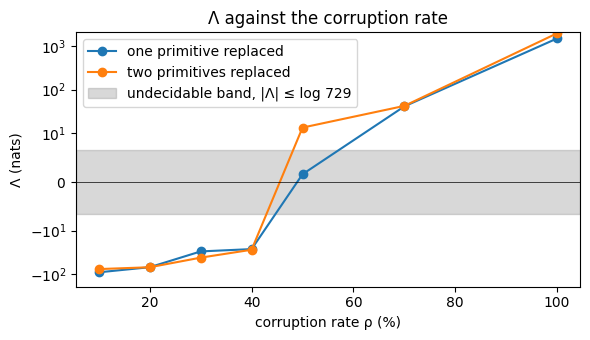

In [4]:
rates = [10, 20, 30, 40, 50, 70, 100]; log_odds = {r["pool"]: r["log_odds"] for r in results}
plt.figure(figsize=(6, 3.5))
for which in ("one primitive", "two primitives"):
    plt.plot(rates, [log_odds[f"{which}, {r}%"] for r in rates], "o-", label=f"{which} replaced")
plt.axhspan(-LOG_M, LOG_M, color="grey", alpha=0.3, label="undecidable band, |Λ| ≤ log 729")
plt.axhline(0, color="k", lw=0.5); plt.yscale("symlog", linthresh=10)
plt.xlabel("corruption rate ρ (%)"); plt.ylabel("Λ (nats)"); plt.legend()
plt.title("Λ against the corruption rate"); plt.tight_layout(); plt.show()

The seven pools of the paper return the true cause with the true hypothesis: no structural repair on the clean pool
and on the pools with 20% of corrupted figures, the swap of red and blue on the shortcut pool (colours are numbered
red 0, yellow 1, blue 2), the true edit on the three symbolic pools. The corrupted pools return no structural repair
up to 40% and flip between 40 and 50%. Where the perception side wins, the column `edit` shows the best losing edit.

## 3. The three conditions

Each pool is checked against the proposition of its cause: Proposition 1 with the rule its labels follow, Proposition 2
with the shortcut of its network, Proposition 3 otherwise. The conditions are those of `diagnosis.ipynb`, sections 4
to 7, with the 165 cells in place of the nine and the (figure, rule) pairs as observations. Their code is in
`kand_helper.py`, and each slack is given at the $\delta$ that makes it largest.

In [5]:
rows = []
for name in POOLS:
    pool = load_pool(name); s0, s1 = score_tables(pool); meta = pool["meta"]
    if meta["cause"] == "wrong rule":
        prop, b = 1, rule_slack(pool, s0, s1, EDITS.index(meta["true_edit"]))
    elif meta["cause"] == "reasoning shortcut":
        prop, b = 2, shortcut_slack(pool, s0, ALPHAS.index(tuple(map(tuple, meta["shortcut"]))))
    else:
        prop, b = 3, noise_slack(pool, s0)
    rows.append(dict(pool=name, cause=meta["cause"], proposition=prop, delta=b["delta"], slack=b["slack"],
                     paper=PAPER[name][1], holds=b["slack"] > 0))
show(rows, ["pool", "cause", "proposition", "delta", "slack", "paper", "holds"],
     {"delta": "{:g}", "slack": "{:+.0f}", "paper": "{:+d}"})
assert all(round(r["slack"]) == r["paper"] for r in rows), "a value differs from the paper"

pool                            cause                    proposition  delta   slack   paper   holds
clean                           none                     3            0.003   +85     +85     True 
shortcut, red <-> blue          reasoning shortcut       2            0.0003  +15013  +15013  True 
dense (all colours different)   wrong rule               1            0.0003  +9811   +9811   True 
local (one comparison flipped)  wrong rule               1            0.0003  +5377   +5377   True 
exception (one cell patched)    wrong rule               1            0.0001  +50     +50     True 
one primitive, 10%              unstructured perception  3            0.001   +54     +54     True 
one primitive, 20%              unstructured perception  3            0.0003  +38     +38     True 
one primitive, 30%              unstructured perception  3            0.001   +1      +1      True 
one primitive, 40%              unstructured perception  3            0.0003  -38     -38     False


The condition of the matching proposition holds on the seven pools of the paper. Proposition 3 holds up to 30% of
corruption with one primitive replaced and 20% with two, while the verdict stays no structural repair up to 40%: as on
MNMath, the condition is sufficient and conservative.